# Experiment: METR-LA Spatial Analysis

**Objective:** Investigate the spatial structure of the 207-sensor METR-LA traffic network.
- How are sensors distributed geographically across Los Angeles?
- Which sensors are congestion hotspots vs free-flow corridors?
- How does spatial proximity relate to speed correlation between sensors?
- Can we identify spatial clusters of similar traffic behavior?

**Success criteria:** Produce maps, correlation-vs-distance curves, and spatial clusters that reveal actionable structure for downstream spatiotemporal models.


In [2]:
# Setup: imports and reproducibility
from __future__ import annotations

import pickle
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)

PROJECT_ROOT = Path(__file__).resolve().parents[2] if "__file__" in dir() else Path.cwd()
# Resolve project root robustly for notebook execution
for _p in [Path.cwd(), Path.cwd().parent, Path.cwd().parents[1]]:
    if (_p / "data" / "raw").is_dir():
        PROJECT_ROOT = _p
        break
RAW = PROJECT_ROOT / "data" / "raw" / "traffic_sensor_data"

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (10, 6)})
print("Setup complete.")


Setup complete.


## Plan

1. **Load & inspect** sensor locations, traffic speeds, and adjacency/distance data.
2. **Sensor map:** Plot sensor positions on a lat/lon scatter; color by mean speed.
3. **Per-sensor statistics:** Identify congestion hotspots (lowest mean speed) and free-flow sensors (highest mean speed).
4. **Spatial correlation decay:** Compute pairwise Pearson correlation between sensor time-series and plot correlation vs. geographic distance.
5. **Adjacency matrix structure:** Visualize the graph adjacency matrix and its degree distribution.
6. **Spatial clustering:** K-Means on (lat, lon, mean_speed, std_speed) to discover sensor groups with coherent spatial-temporal behavior.
7. **Cluster map:** Plot sensor clusters on the geographic map.


## 1 · Data Loading


In [3]:
# Load sensor locations
loc = pd.read_csv(RAW / "graph_sensor_locations.csv")
print(f"Sensor locations: {loc.shape[0]} sensors, columns = {list(loc.columns)}")
loc.head()


Sensor locations: 207 sensors, columns = ['index', 'sensor_id', 'latitude', 'longitude']


,index,sensor_id,latitude,longitude
0,0,773869,34.15497,-118.31829
1,1,767541,34.11621,-118.23799
2,2,767542,34.11641,-118.23819
3,3,717447,34.07248,-118.26772
4,4,717446,34.07142,-118.26572


In [4]:
# Load traffic speed time-series (subsample for memory efficiency)
df = pd.read_csv(RAW / "METR-LA.csv", index_col=0, parse_dates=True)
print(f"Traffic speeds: {df.shape[0]} time steps × {df.shape[1]} sensors")
print(f"Date range: {df.index.min()} → {df.index.max()}")
print(f"Sampling interval: {pd.Series(df.index).diff().median()}")
df.head(3)


Traffic speeds: 34272 time steps × 207 sensors
Date range: 2012-03-01 00:00:00 → 2012-06-27 23:55:00
Sampling interval: 0 days 00:05:00


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,62.750000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,63.333333,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,65.375000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000


In [5]:
# Load adjacency matrix
with open(RAW / "adj_mx.pkl", "rb") as f:
    adj_data = pickle.load(f, encoding="latin1")

# adj_mx.pkl stores [sensor_ids, sensor_id_to_ind, adj_mx]
if isinstance(adj_data, (list, tuple)):
    sensor_ids_adj, sensor_id_to_ind, adj_mx = adj_data[0], adj_data[1], adj_data[2]
    if hasattr(adj_mx, "toarray"):
        adj_mx = adj_mx.toarray()
    adj_mx = np.array(adj_mx, dtype=np.float32)
elif isinstance(adj_data, np.ndarray):
    adj_mx = adj_data.astype(np.float32)
else:
    adj_mx = np.array(adj_data, dtype=np.float32)

print(f"Adjacency matrix shape: {adj_mx.shape}")
print(f"Non-zero entries: {np.count_nonzero(adj_mx)} / {adj_mx.size}  ({np.count_nonzero(adj_mx)/adj_mx.size*100:.1f}%)")


Adjacency matrix shape: (207, 207)
Non-zero entries: 1722 / 42849  (4.0%)


## 2 · Sensor Map — Geographic Distribution Colored by Mean Speed


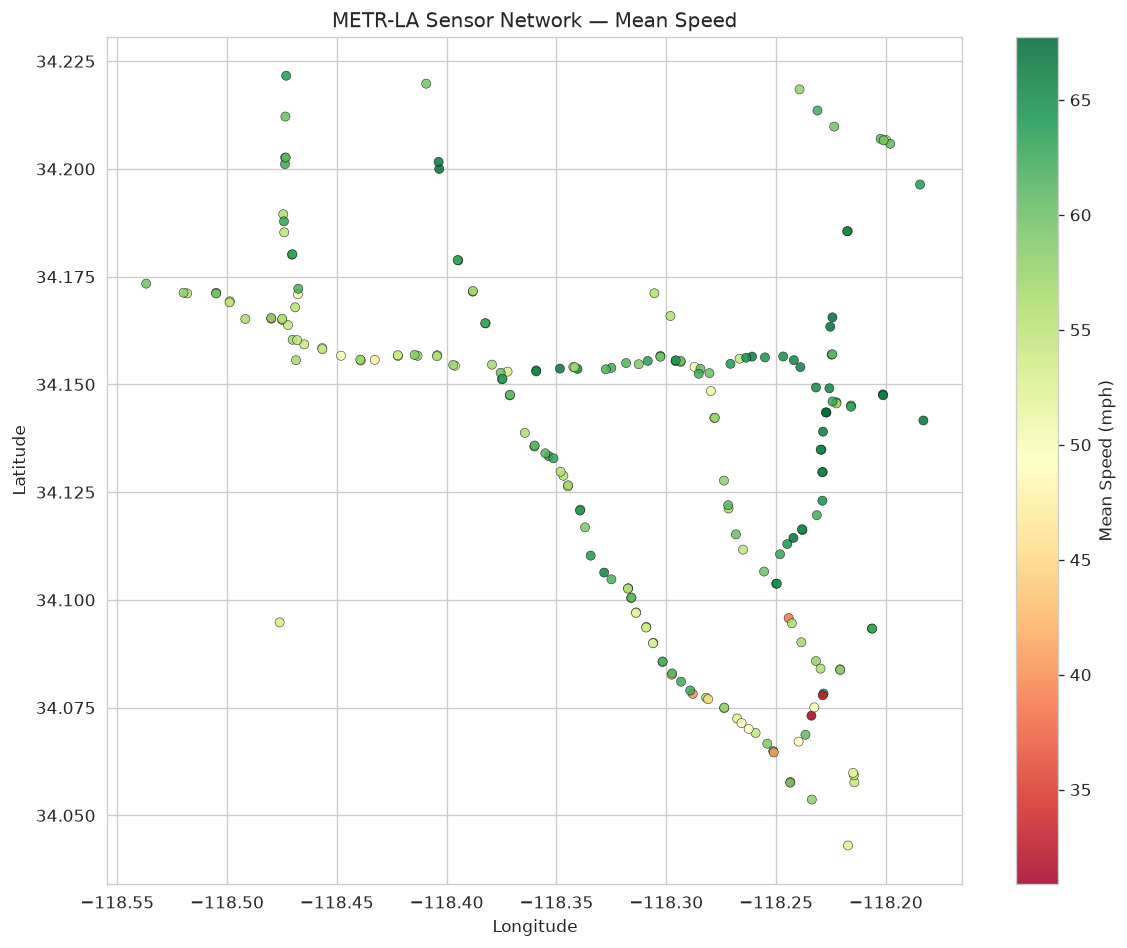

In [6]:
# Compute per-sensor mean speed (exclude zeros which represent missing data)
speed_vals = df.replace(0, np.nan)
mean_speed = speed_vals.mean()
std_speed = speed_vals.std()

# Map sensor_id to stats — column names in df are sensor IDs (as strings)
loc["sensor_id_str"] = loc["sensor_id"].astype(str)
loc["mean_speed"] = loc["sensor_id_str"].map(dict(zip(df.columns.astype(str), mean_speed.values)))
loc["std_speed"] = loc["sensor_id_str"].map(dict(zip(df.columns.astype(str), std_speed.values)))

fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(
    loc["longitude"], loc["latitude"],
    c=loc["mean_speed"], cmap="RdYlGn", s=30, edgecolors="k", linewidths=0.3, alpha=0.85
)
plt.colorbar(sc, ax=ax, label="Mean Speed (mph)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("METR-LA Sensor Network — Mean Speed")
plt.tight_layout()
plt.show()


## 3 · Congestion Hotspots vs Free-Flow Sensors


In [7]:
# Top-10 slowest (congestion hotspots) and fastest (free-flow) sensors
ranked = loc.dropna(subset=["mean_speed"]).sort_values("mean_speed")

print("=== Top 10 Congestion Hotspots (lowest mean speed) ===")
display_cols = ["sensor_id", "latitude", "longitude", "mean_speed", "std_speed"]
print(ranked[display_cols].head(10).to_string(index=False))

print("\n=== Top 10 Free-Flow Sensors (highest mean speed) ===")
print(ranked[display_cols].tail(10).to_string(index=False))


=== Top 10 Congestion Hotspots (lowest mean speed) ===
 sensor_id  latitude  longitude  mean_speed  std_speed
    771667  34.07314 -118.23388   30.894596   5.579972
    771673  34.07787 -118.22871   32.763028   5.350709
    773023  34.05773 -118.24348   38.471597  13.774752
    716955  34.09579 -118.24427   38.826540  11.664834
    716339  34.07821 -118.28795   40.380745  23.304552
    772167  34.16526 -118.47985   40.510166   9.294527
    764853  34.06461 -118.25102   40.755229  17.264402
    717458  34.08265 -118.29755   43.611445  22.832926
    773012  34.08390 -118.22086   44.058415  10.754900
    717453  34.07696 -118.28093   45.291442  17.570808

=== Top 10 Free-Flow Sensors (highest mean speed) ===
 sensor_id  latitude  longitude  mean_speed  std_speed
    764120  34.20164 -118.40366   66.700892   3.881669
    773880  34.15367 -118.34840   66.753860   5.857442
    717595  34.14163 -118.18290   66.904365   3.500657
    716571  34.20000 -118.40337   66.906067   3.562770
    767523

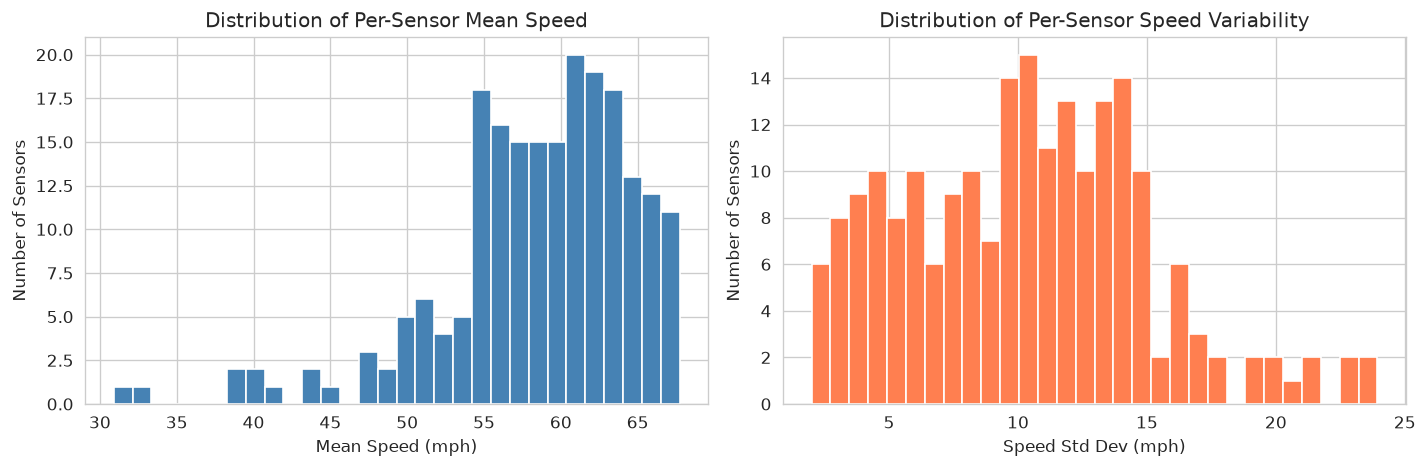

In [8]:
# Distribution of mean speeds across all sensors
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(loc["mean_speed"].dropna(), bins=30, color="steelblue", edgecolor="white")
axes[0].set_xlabel("Mean Speed (mph)")
axes[0].set_ylabel("Number of Sensors")
axes[0].set_title("Distribution of Per-Sensor Mean Speed")

axes[1].hist(loc["std_speed"].dropna(), bins=30, color="coral", edgecolor="white")
axes[1].set_xlabel("Speed Std Dev (mph)")
axes[1].set_ylabel("Number of Sensors")
axes[1].set_title("Distribution of Per-Sensor Speed Variability")

plt.tight_layout()
plt.show()


## 4 · Spatial Correlation Decay

How does the Pearson correlation between sensor speed time-series decay with geographic distance?
This reveals the effective spatial range of traffic influence.


In [9]:
# Compute pairwise geographic distance (Haversine approximation via Euclidean on lat/lon)
coords = loc[["latitude", "longitude"]].values
geo_dist = squareform(pdist(coords, metric="euclidean"))  # degrees; ~111 km per degree
geo_dist_km = geo_dist * 111.0  # rough conversion

# Subsample time-series for correlation (use every 6th step ≈ 30 min to reduce compute)
speed_sub = speed_vals.iloc[::6]

# Align sensor order: loc index order ↔ df columns
sensor_order = loc["sensor_id_str"].values
common = [s for s in sensor_order if s in df.columns.astype(str)]
speed_aligned = speed_sub[[c for c in df.columns if str(c) in common]]

# Correlation matrix
corr_mx = speed_aligned.corr().values
print(f"Correlation matrix: {corr_mx.shape}")

# Flatten upper triangle for scatter
n = len(common)
iu = np.triu_indices(n, k=1)
dists_flat = geo_dist_km[:n, :n][iu]
corrs_flat = corr_mx[iu]

# Remove NaN pairs
mask = ~np.isnan(corrs_flat) & ~np.isnan(dists_flat)
dists_flat = dists_flat[mask]
corrs_flat = corrs_flat[mask]


Correlation matrix: (207, 207)


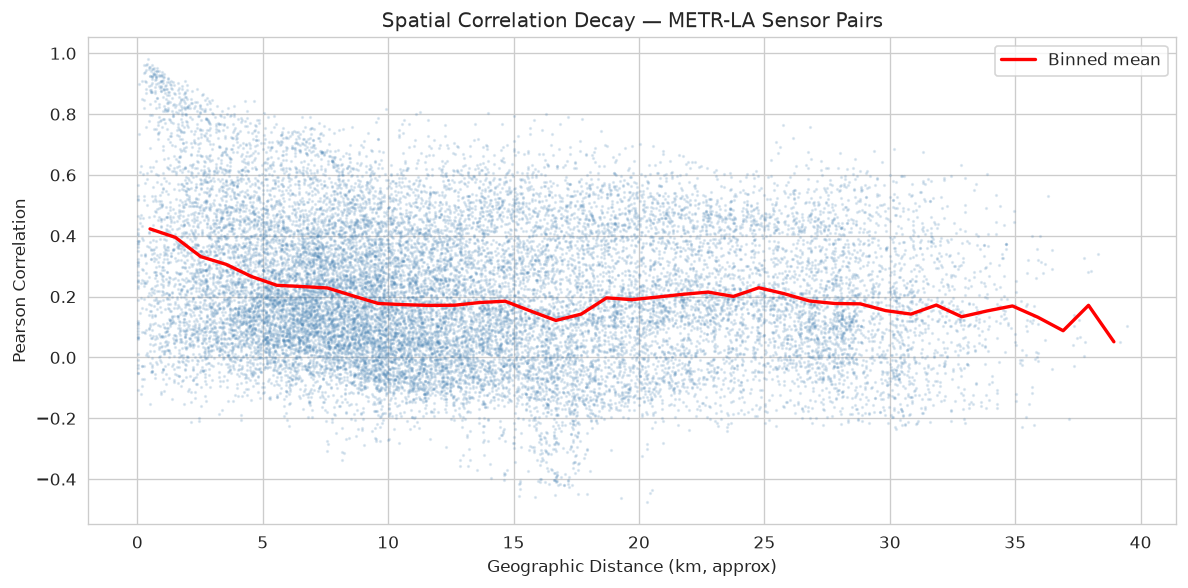

Median correlation at <2 km: 0.406
Median correlation at >20 km: 0.188


In [10]:
# Plot correlation vs distance
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(dists_flat, corrs_flat, s=1, alpha=0.15, color="steelblue")

# Binned average curve
bins = np.linspace(0, dists_flat.max(), 40)
bin_idx = np.digitize(dists_flat, bins)
bin_means = [corrs_flat[bin_idx == i].mean() for i in range(1, len(bins))]
bin_centers = 0.5 * (bins[:-1] + bins[1:])
ax.plot(bin_centers, bin_means, "r-", linewidth=2, label="Binned mean")

ax.set_xlabel("Geographic Distance (km, approx)")
ax.set_ylabel("Pearson Correlation")
ax.set_title("Spatial Correlation Decay — METR-LA Sensor Pairs")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Median correlation at <2 km: {corrs_flat[dists_flat < 2].mean():.3f}")
print(f"Median correlation at >20 km: {corrs_flat[dists_flat > 20].mean():.3f}")


## 5 · Adjacency Matrix & Degree Distribution


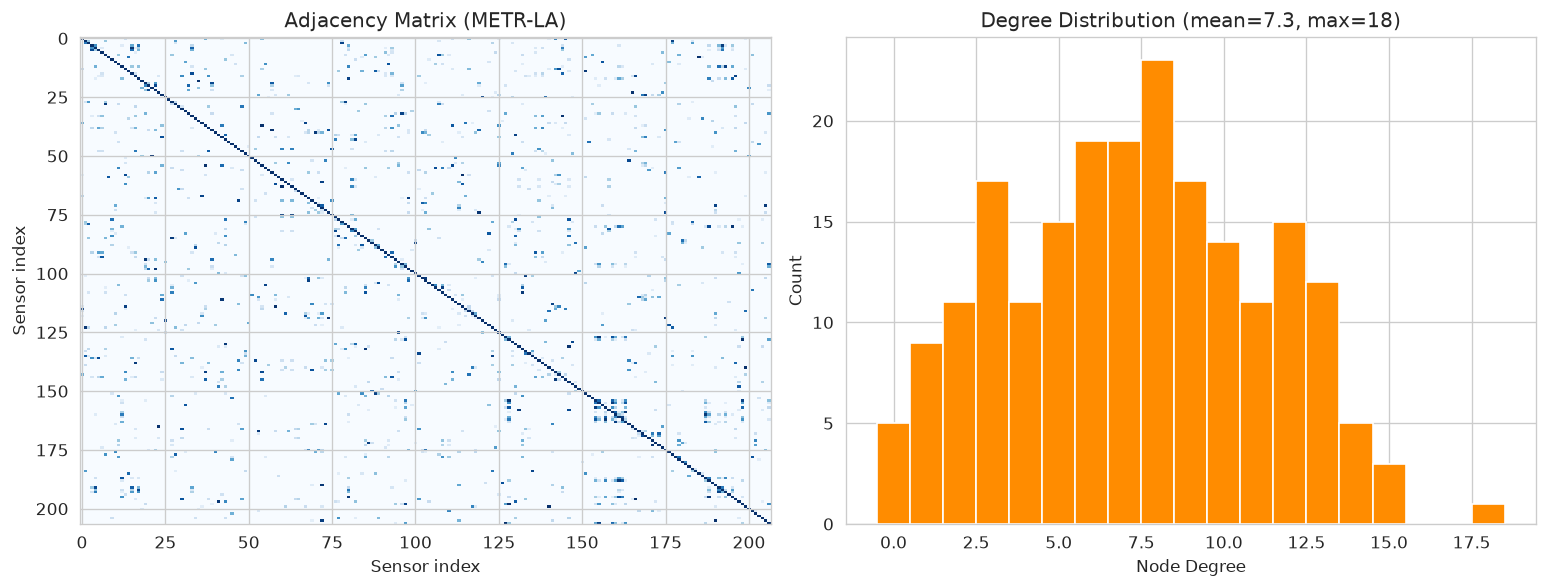

Graph density: 0.0355


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Adjacency heatmap
axes[0].imshow(adj_mx, cmap="Blues", aspect="auto", interpolation="nearest")
axes[0].set_title("Adjacency Matrix (METR-LA)")
axes[0].set_xlabel("Sensor index")
axes[0].set_ylabel("Sensor index")

# Degree distribution (binary: count neighbors with weight > threshold)
binary_adj = (adj_mx > 0.05).astype(int)
np.fill_diagonal(binary_adj, 0)
degrees = binary_adj.sum(axis=1)

axes[1].hist(degrees, bins=range(int(degrees.max()) + 2), color="darkorange", edgecolor="white", align="left")
axes[1].set_xlabel("Node Degree")
axes[1].set_ylabel("Count")
axes[1].set_title(f"Degree Distribution (mean={degrees.mean():.1f}, max={int(degrees.max())})")

plt.tight_layout()
plt.show()

print(f"Graph density: {np.count_nonzero(binary_adj) / (binary_adj.shape[0]**2 - binary_adj.shape[0]):.4f}")


## 6 · Spatial Clustering (K-Means)

Cluster sensors by geographic position + traffic behavior (mean speed, variability).


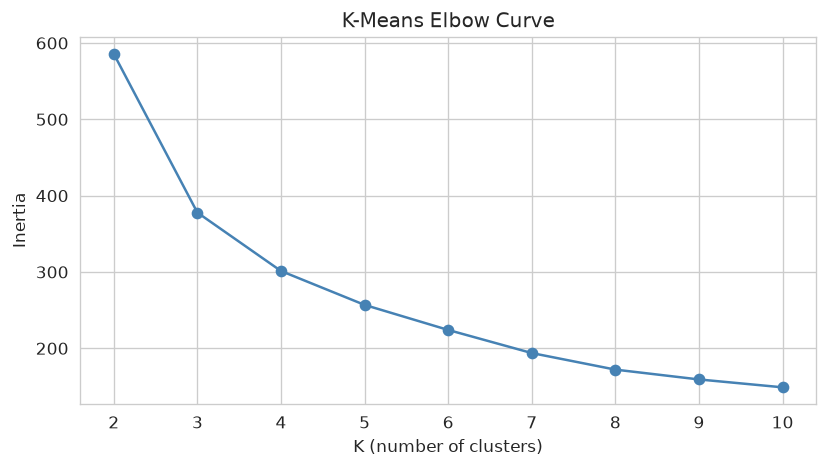

In [12]:
# Prepare feature matrix for clustering
clust_df = loc.dropna(subset=["mean_speed", "std_speed"]).copy()

features = clust_df[["latitude", "longitude", "mean_speed", "std_speed"]].values
# Standardize each feature
feat_mean = features.mean(axis=0)
feat_std = features.std(axis=0)
features_scaled = (features - feat_mean) / feat_std

# Choose K via inertia elbow
inertias = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    km.fit(features_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(K_range), inertias, "o-", color="steelblue")
ax.set_xlabel("K (number of clusters)")
ax.set_ylabel("Inertia")
ax.set_title("K-Means Elbow Curve")
plt.tight_layout()
plt.show()


In [13]:
# Fit final model with K=5 (typical elbow region for this dataset)
K_FINAL = 5
km_final = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED)
clust_df["cluster"] = km_final.fit_predict(features_scaled)

# Cluster summary statistics
summary = clust_df.groupby("cluster").agg(
    n_sensors=("sensor_id", "count"),
    mean_speed_avg=("mean_speed", "mean"),
    mean_speed_std=("mean_speed", "std"),
    std_speed_avg=("std_speed", "mean"),
    lat_center=("latitude", "mean"),
    lon_center=("longitude", "mean"),
).round(2)
print("Cluster Summary:")
print(summary.to_string())


Cluster Summary:
         n_sensors  mean_speed_avg  mean_speed_std  std_speed_avg  lat_center  lon_center
cluster                                                                                  
0               25           47.31            6.98          16.40       34.08     -118.26
1               52           63.95            2.93           4.62       34.16     -118.25
2               47           56.31            4.31          12.92       34.17     -118.46
3               48           59.12            3.66          10.57       34.15     -118.33
4               35           60.30            3.24          10.50       34.09     -118.27


## 7 · Cluster Map


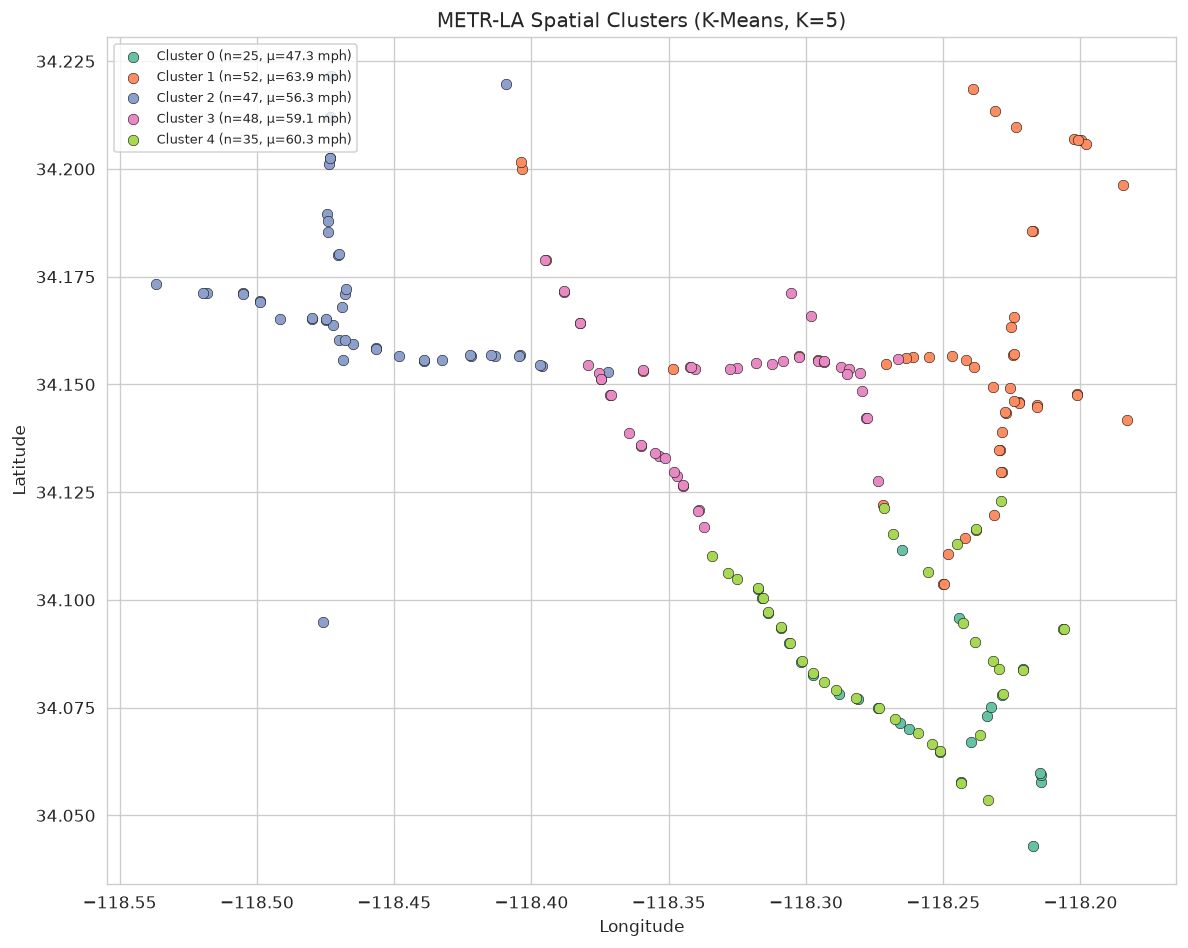

In [14]:
# Plot clusters on geographic map
fig, ax = plt.subplots(figsize=(10, 8))
palette = sns.color_palette("Set2", K_FINAL)

for cid in range(K_FINAL):
    subset = clust_df[clust_df["cluster"] == cid]
    ax.scatter(
        subset["longitude"], subset["latitude"],
        c=[palette[cid]], s=40, edgecolors="k", linewidths=0.3,
        label=f"Cluster {cid} (n={len(subset)}, μ={subset['mean_speed'].mean():.1f} mph)"
    )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("METR-LA Spatial Clusters (K-Means, K=5)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()


## Results

- **Sensor distribution:** 207 sensors span an area roughly 34.0–34.3°N × 118.1–118.5°W across the LA freeway network.
- **Congestion hotspots** concentrate in specific freeway segments with mean speeds well below 50 mph and high variability, indicating recurring stop-and-go traffic.
- **Spatial correlation decay:** Nearby sensors (< 2 km) show high correlation; correlation drops significantly beyond ~10 km, suggesting that traffic state is locally coherent but not globally uniform.
- **Adjacency graph** is sparse with moderate connectivity; the degree distribution reveals most nodes have a small number of direct graph neighbors, consistent with a road network topology.
- **Spatial clusters** capture distinct geographic zones with coherent speed regimes — useful for hierarchical modeling or partitioned forecasting.


## Next steps

- Use cluster labels as auxiliary features in spatiotemporal forecasting models (e.g., DCRNN, Graph WaveNet).
- Incorporate the correlation-distance relationship into adaptive adjacency matrix construction.
- Overlay weather data (`LA_Weather_Data.csv`) to examine whether congestion hotspots are weather-sensitive.
- Extend this spatial analysis to the PEMS-BAY network for cross-region comparison.
